In [18]:
import sys

sys.path.append("..")
import matplotlib.pyplot as plt
from pathlib import Path
import plotly.express as px
import numpy as np
from classes.sample.raw_data import INCFile, LMSFile
import pandas as pd
from scipy.signal import freqz, tf2zpk, csd, welch, firwin, lfilter
from librosa import lpc

In [3]:
raw_path = Path(os.getenv('RAW_DATA_PATH', 'data/raw'))

In [6]:
lms_file = LMSFile.from_txt(lms_path)

In [260]:
cable = 1
y = getattr(lms_file, f"c{cable}_y")

x = lms_file.input_force

dt = lms_file.dt
fs = 1/dt
t = np.linspace(0, dt*len(y), len(y))

In [261]:
def bandpass(x: pd.DataFrame, f1: float, f2: float):
    dt = x.index[1] - x.index[0]
    h = firwin(127, [f1, f2], fs=1/dt, pass_zero="bandpass")
    return x.apply(lambda xx: lfilter(h, 1, xx))

In [262]:
# FRF
frf_freq, xx = welch(x=x, fs=fs, window="hann", nperseg=2048)
_, yy = welch(x=y, fs=fs, window="hann", nperseg=2048)
_, xy = csd(x=x, y=y, fs=fs, nperseg=2048, window="hamming")
_, yx = csd(x=y, y=x, fs=fs, nperseg=2048, window="hamming")

frf = xy / xx  # h1
# frf = yy / yx # h2

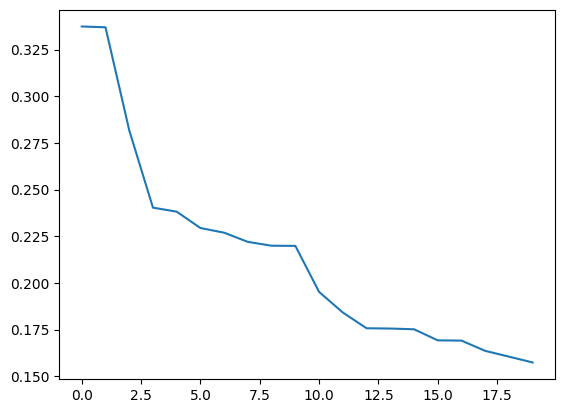

In [263]:
# LPC

errors = []
rms = np.sqrt(np.mean(np.square(np.array(y))))
for order in range(10,30):
    a_lpc = lpc(np.array(y), order=order)
    freq_lpc, h_lpc = freqz(a=a_lpc, b=1, fs=fs)
    zeros, poles, r = tf2zpk(a=1, b=a_lpc)
    omega_zeros = np.angle(zeros)
    freq_zeros_hz = (omega_zeros * fs) / (2 * np.pi)

    # error
    e = lfilter(b=a_lpc, a=1, x=np.array(y))
    e_rms = np.sqrt(np.mean(np.square(e)))
    errors.append(e_rms/rms)
plt.plot(errors)

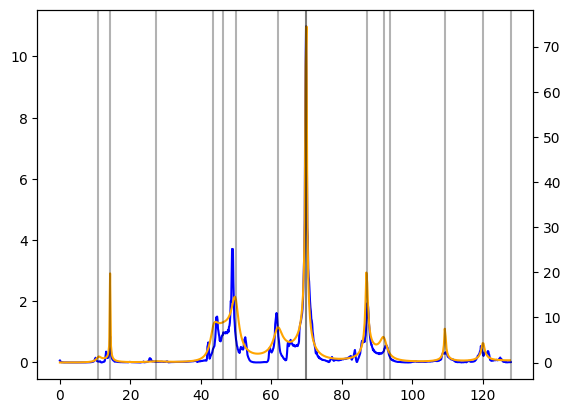

In [264]:
fig = plt.figure()
ax = fig.add_subplot()
ax.plot(frf_freq, np.abs(frf), color="blue")
ax2 = ax.twinx()
ax2.plot(freq_lpc, np.abs(h_lpc), color="orange")
for fz in freq_zeros_hz:
    if fz < 0:
        continue
    ax2.axvline(fz, color="k", alpha=0.3)

In [265]:
def is_pole_relevant(pole: complex, all_poles: np.ndarray) -> bool:
    # corresponding frequency point
    w = np.angle(pole)
    fi = (w * fs) / (2 * np.pi)
    pi = np.cos(2*np.pi*fi/fs) + 1j*np.sin(2*np.pi*fi/fs)

    # distances
    pole_dist = np.abs(pole - pi)
    min_dist = np.min(np.abs(all_poles - pi))

    return pole_dist == min_dist

In [266]:
relevance = [is_pole_relevant(z, zeros) for z in zeros]

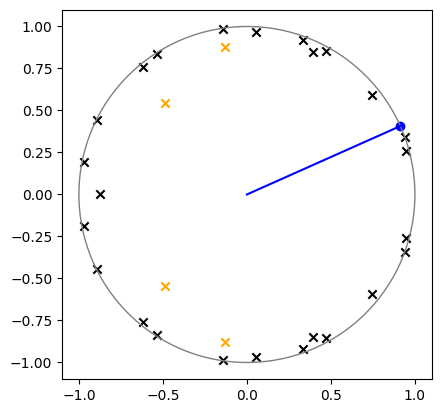

In [267]:
fi = 17.09017682
fs = 1 / dt
xi = np.cos(2*np.pi*fi/fs)
yi = np.sin(2*np.pi*fi/fs)

fig = plt.figure()
ax = fig.add_subplot(1, 1, 1)
circ = plt.Circle((0, 0), radius=1, edgecolor='gray', facecolor='None')
for z, is_relevant in zip(zeros, relevance):
    if is_relevant:
        color = "k"
    else:
        color = "orange"
    ax.scatter(np.real(z), np.imag(z), color=color, marker="x")
ax.scatter(xi, yi, color="blue")
ax.plot([0,xi], [0, yi], color="blue")
ax.add_patch(circ)
ax.set_aspect('equal', 'box')
